# **Treinamento e comparação dos modelos**

## **Objetivo**

Comparar os classificadores da **Saikit-learn do grupo** no dataset MAGIC Gamma, selecionar uma configuração pela validação e registrar os resultados de forma reproduzível.

Esta etapa contempla:

1. Escolha e configuração dos modelos.
2. Treinamento com a biblioteca do grupo.
3. Comparação por métricas e gráficos.
4. Registro das métricas, previsões e configurações.

In [ ]:
# Instalação das bibliotecas
%pip install saikit-learn numpy pandas matplotlib nbformat

  Using cached nbformat-5.11.1-py3-none-any.whl.metadata (3.7 kB)
Using cached nbformat-5.11.1-py3-none-any.whl (79 kB)

   ---------------------------------------- 0/2 [fastjsonschema]
   -------------------- ------------------- 1/2 [nbformat]
   -------------------- ------------------- 1/2 [nbformat]
   -------------------- ------------------- 1/2 [nbformat]
   ---------------------------------------- 2/2 [nbformat]

Note: you may need to restart the kernel to use updated packages.


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import saikit_learn

from saikit_learn.linear_model import LogisticRegression
from saikit_learn.neighbors import KNN
from saikit_learn.discriminant_analysis import LDA, QDA
from saikit_learn.classification_metrics import ClassificationMetrics

print(f'Versão da Saikit-learn: {saikit_learn.__version__}')


Versão da Saikit-learn: 0.3.1


## **2. Reutilização do pré-processamento**

Pegamos os dados de treino salvos do notebook anterior, com isso carregaremos ele para esse notebook a fimm de executar os treinos e avaliar os modelos.


In [4]:
d = np.load("../../../data/processed/magic_split.npz")
X_train, y_train = d["X_train"], d["y_train"].astype(int)
X_val,   y_val   = d["X_val"],   d["y_val"].astype(int)
print(X_train.shape, np.bincount(y_train))

(13314, 10) [4664 8650]


## **3. Escolha e configuração dos modelos**

Comparamos quatro configurações iniciais:

| Modelo | Característica |
|---|---|
| Regressão logística | Fronteira de decisão linear |
| KNN | Classificação por proximidade, com cinco vizinhos (padrão) |
| LDA | Uma matriz de covariância comum às classes |
| QDA | Uma matriz de covariância para cada classe |

Os parâmetros ficarão centralizados no código abaixo. Já as configurações são apenas um ponto de partida, pois esta etapa não visa a busca exaustiva de
hiperparâmetros, sendo o enfoque da próxima parte. A seleção será feita entre essas configurações.

Por fim, calculamos uma referência simples de prever todas as observações a classe mais frequente **no treino**. Isso será feito para interpretar os ganhos dos classificadores.


In [8]:
model_specs = {
    'logistic_regression': {
        'name': 'Regressão logística',
        'constructor': LogisticRegression,
        'parameters': {'learning_rate': 0.5, 'max_iter': 10000, 'tol': 1e-6, 'alpha': 0.0},
    },
    'knn': {
        'name': 'KNN (k=5)',
        'constructor': KNN,
        'parameters': {'k': 5, 'p': 2},
    },
    'lda': {'name': 'LDA', 'constructor': LDA, 'parameters': {}},
    'qda': {'name': 'QDA', 'constructor': QDA, 'parameters': {'reg_param': 0.0}},
}
models = {
    model_id: specification['constructor'](**specification['parameters'])
    for model_id, specification in model_specs.items()
}

display(pd.DataFrame([
    {'Modelo': specification['name'], 'Parâmetros': specification['parameters']}
    for specification in model_specs.values()
]))


,Modelo,Parâmetros
0,Regressão logística,"{'learning_rate': 0.5, 'max_iter': 10000, 'tol..."
1,KNN (k=5),"{'k': 5, 'p': 2}"
2,LDA,{}
3,QDA,{'reg_param': 0.0}


## **4. Métricas e critério de comparação**

Para quantificar as métricas são calculadas pelo método de `ClassificationMetrics`. A matriz de confusão tem linhas para as classes reais e colunas para as previstas, na ordem [h, g].

Os modelos são comparados pelo maior F1 macro na validação. Em caso de empate, será escolhida a menor taxa de falsos positivos (hádrons classificados como gama).

A escolha do F1 macro resume-se ao fato das classes serem desbalanceadas (cerca de 65% gama), logo prever sempre gama já daria ao entorno de 65% de acurácia. 
Como o F1 macro dá o mesmo peso às duas classes, a métrica só é alta se o modelo for bem em ambas. Ele não distingue o tipo de erro, e no MAGIC classificar hádron como gama é mais grave. Por isso é só um critério inicial, e a taxa de falsos positivos é analisada depois.

In [9]:
def compute_metrics(y_true, y_pred):
    m = ClassificationMetrics(y_true, y_pred, labels=[0, 1])
    confusion = m.confusion_matrix()
    tn, fp, fn, tp = confusion.ravel()
    metrics = {
        'accuracy': m.score('accuracy'),
        'f1_macro': m.score('f1', average='macro'),
        'false_positive_rate': fp / (fp + tn),
    }
    return metrics, confusion

majority = np.bincount(y_train).argmax()
baseline_pred = np.full_like(y_val, majority)
baseline_metrics, _ = compute_metrics(y_val, baseline_pred)

## **5. Treinamento e avaliação na validação**

Todos os modelos são ajustados no treino e avaliados nessa mesma validação.
Registramos os tempos de treino e previsão separadamente, com o KNN realizando grande parte ao prever novas observações.

Também verificamos a convergência da regressão logística. Caso ela não
convirja, sua configuração precisa ser revista antes da comparação final.

In [10]:
rows = []
confusions = {}

for model_id, model in models.items():
    model.fit(X_train, y_train)
    pred = np.asarray(model.predict(X_val), dtype=int).reshape(-1)
    metrics, confusions[model_id] = compute_metrics(y_val, pred)
    rows.append({'model_id': model_id, 'model_name': model_specs[model_id]['name'], **metrics})

results = pd.DataFrame(rows).sort_values(
    ['f1_macro', 'false_positive_rate', 'model_id'],
    ascending=[False, True, True]).reset_index(drop=True)

baseline = pd.DataFrame([{'model_name': 'Classe majoritária', **baseline_metrics}])
display(pd.concat([results, baseline]).round(4))

,model_id,model_name,accuracy,f1_macro,false_positive_rate
0,knn,KNN (k=5),0.8258,0.7999,0.3562
1,logistic_regression,Regressão logística,0.7753,0.7441,0.4114
2,qda,QDA,0.7869,0.7430,0.4840
3,lda,LDA,0.7669,0.7299,0.4521
0,NaN,Classe majoritária,0.6379,0.3895,1.0000


## **6. Comparação visual dos resultados**

O primeiro gráfico compara F1 macro, já o segundo destaca a taxa de falsos
positivos. Valores maiores são desejáveis no primeiro, indicando melhor treino e menores no segundo, indicando a menor taxa de um má classificação. A linha tracejada apresenta a referência da classe majoritária.


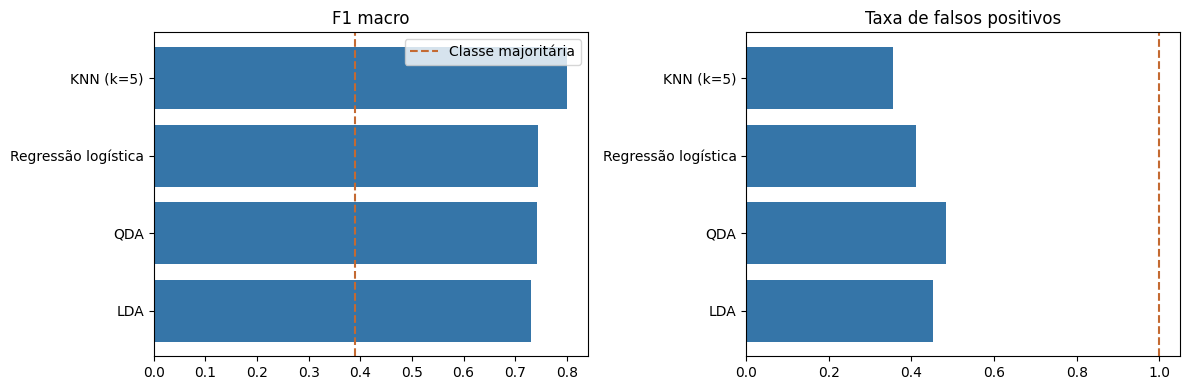

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
names = results['model_name']

for ax, metric, title in [(axes[0], 'f1_macro', 'F1 macro'),
                          (axes[1], 'false_positive_rate', 'Taxa de falsos positivos')]:
    ax.barh(names, results[metric], color='#3575A8')
    ax.axvline(baseline_metrics[metric], color='#C46A32', linestyle='--', label='Classe majoritária')
    ax.invert_yaxis()
    ax.set_title(title)

axes[0].legend()
plt.tight_layout()
plt.show()

## **8. Matrizes de confusão**

Nas matrizes, as linhas são as classes reais e as colunas são as classes previstas, na ordem [h, g]. A diagonal mostra os acertos. Fora dela:

Primeira linha, segunda coluna: hádrons classificados como gama (falsos positivos), o erro no MAGIC.
Segunda linha, primeira coluna: gamas classificados como hádron (falsos negativos).


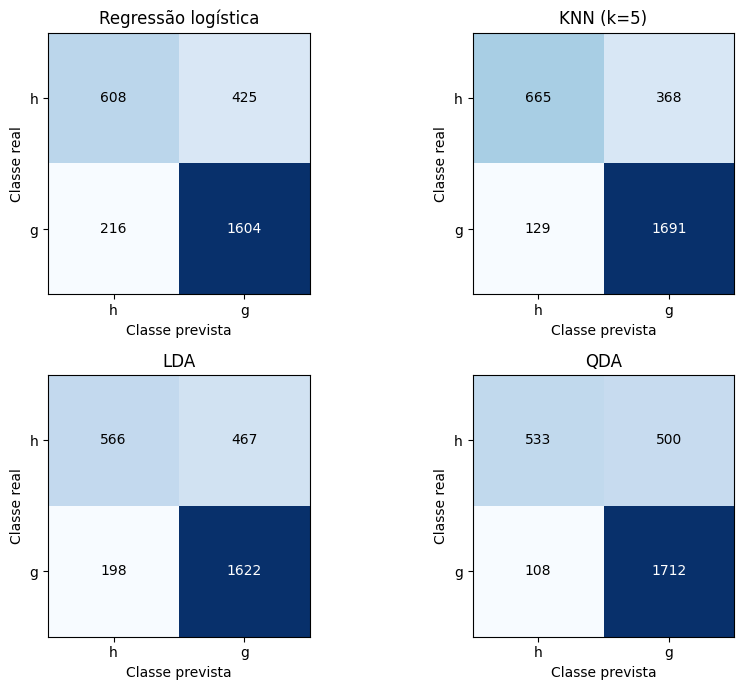

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(9, 7))
for ax, (model_id, cm) in zip(axes.ravel(), confusions.items()):
    ax.imshow(cm, cmap='Blues')
    for i in range(2):
        for j in range(2):
            color = 'white' if cm[i, j] > cm.max() / 2 else 'black'
            ax.text(j, i, f'{cm[i, j]:.0f}', ha='center', va='center', color=color)
    ax.set_xticks([0, 1], ['h', 'g'])
    ax.set_yticks([0, 1], ['h', 'g'])
    ax.set(xlabel='Classe prevista', ylabel='Classe real', title=model_specs[model_id]['name'])
plt.tight_layout()
plt.show()

## *Conclusão da parte 3*

Os quatro classificadores foram comparados com os mesmos dados de treino e validação, usando o F1 macro como critério de seleção. O KNN (com k = 5) teve o melhor desempenho, mas todos os modelos apresentaram uma taxa significativa de falsos positivos (35% a 48%).

Na próxima etapa, verificaremos a escolha dos hiperparâmetros e nos assegurar de seu melhor tratamento.

